# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", ...)
print("usage", ...)

plans (2, 8)
users Ellipsis
usage Ellipsis


In [7]:
# inspección de plans con .info()
plans .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users .isna() .sum())# Cantidad de valores nulos
print(users .isna(). mean() *100)# Proporción de valores nulos

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage .isna() .sum())# Cantidad de valores nulos
print(usage .isna(). mean() *100)# Proporción de valores nulos

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
 - users: Tiene valores faltantes en city con un 11.73%, y churn_date con un 88.35%.
 - usage: Tiene valores faltantes en date con un 0.125%, duration con un 55.19% y length con un 44.74%.
- Indica qué harías: ¿imputar, eliminar, ignorar?
 - Users - city: Se imputaría (por ejemplo, con "Desconocido" o el valor más frecuente) ya que es un dato importante para la segmentación de clientes.
 - Usage - date: Al tener un porcentaje tan bajo (<1%), se pueden eliminar esas filas directamente o imputar corrigiendo el formato de fecha.
 - Usage - duration y length: Se debe investigar si los nulos son mutuamente excluyentes (es decir, un registro de llamada tiene duración pero no megas, y viceversa). Dependiendo de esto, se dejarían como nulos o se    imputarían con ceros para el servicio no utilizado.
 

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
columnas_numericas = users.select_dtypes(include='number').columns
print(users[columnas_numericas] .describe())
print()
print('Cantidad_casos_inusuales_-999') 
users['age'].isin([-999]).sum() #sumo_todos_los_casos_donde_la_edad_sea_-999

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000

Cantidad_casos_inusuales_-999


55

- La columna `user_id` .No presenta datos atípicos. Sus estadísticas muestran una distribución uniforme que va desde 10000 hasta 13999. Esto es correcto y esperado, ya que al ser un identificador único (variable categórica), sus métricas estadísticas (media, desviación estándar, cuartiles) no tienen una interpretación matemática real, sino que reflejan una secuencia lógica sin anomalías aparentes.
- La columna `age` Contiene un valor mínimo irreal de -999 que se repite en 55 registros. El resto de la distribución es coherente (edades entre 32 y 79 años). Este valor de -999 es claramente un error de captura o un nulo enmascarado que debe ser reemplazado por NaN o imputado para no sesgar el análisis estadístico posterior.

In [13]:
# explorar columnas numéricas de usage
columnas_numericas = usage.select_dtypes(include='number').columns
print(usage[columnas_numericas] .describe())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id`No presentan datos faltantes (ambas registran 40,000 conteos) ni atípicos. El id es la clave secuencial de cada transacción, mientras que user_id identifica al cliente. Es el comportamiento esperado que haya más registros que usuarios únicos, ya que un cliente genera múltiples eventos de consumo. Al ser variables categóricas, sus promedios y desviaciones no tienen valor analítico.
- Las columnas duration y length: Presentan una falta importante de datos, ya que sus conteos no alcanzan los 40,000 totales. Sus valores mínimos son 0.0, lo que sugiere llamadas no contestadas, consumo nulo o sesiones fallidas que requieren exploración adicional.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user: 
    print(col)
    print(users[col].value_counts())
    print()

city
Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

plan
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` Presenta una lista de ciudades con un hallazgo importante: existen 96 registros etiquetados con el carácter ?. Esto es un claro ejemplo de un valor nulo enmascarado o error de captura que debe ser reemplazado por NaN o imputado (por ejemplo, con "Desconocido" o la moda) para limpiar el dataset. Las demás ciudades (Bogotá, CDMX, Medellín, etc.) presentan frecuencias normales
- La columna `plan` Muestra datos limpios y consistentes, conformados únicamente por dos categorías válidas: "Basico" y "Premium". No se detectan valores extraños ni nulos, y revela a nivel descriptivo que la mayoría de los usuarios (2,595) optan por el plan básico frente al premium (1,405).

In [15]:
# explorar columna categórica de usage
usage['type'].value_counts()# completa el código

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` Presenta datos limpios compuestos exclusivamente por dos categorías válidas y esperadas ("text" y "call"), sin errores de escritura ni valores nulos enmascarados. A nivel de comportamiento del cliente, revela que existe una mayor frecuencia en el envío de mensajes de texto (22,092 registros) en comparación con la realización de llamadas telefónicas (17,908 registros).


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- En la columna `age` (de la tabla users), se identificó el valor centinela numérico `-999`  repetido en `55` registros.
- En la columna `city` (de la tabla users), se encontró el carácter inválido `?` en `96` registros. 
- ¿Qué acción tomarías?
- Para age: Reemplazar el valor -999 por nulo (NaN). Es crítico realizar este cambio antes de cualquier análisis numérico para evitar que este valor artificial sesgue la media, la desviación estándar y los gráficos    de distribución de edades. Posteriormente, se puede evaluar si imputar con la mediana.
- Para city: Reemplazar el carácter ? por NaN o transformarlo en una categoría explícita como "Desconocido". Esto limpia el formato de texto y permite tratar correctamente estos casos como datos faltantes al momento    de agrupar o segmentar por ciudad.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
#Copia_limpia_del_Dataset_users
users_limpio = users.copy()
# Convertir a fecha la columna `reg_date` de users
users_limpio['reg_date'] = pd.to_datetime(users_limpio['reg_date'])
users_limpio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     4000 non-null   int64         
 1   first_name  4000 non-null   object        
 2   last_name   4000 non-null   object        
 3   age         4000 non-null   int64         
 4   city        3531 non-null   object        
 5   reg_date    4000 non-null   datetime64[ns]
 6   plan        4000 non-null   object        
 7   churn_date  466 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 250.1+ KB


In [17]:
#Copia_limpia_del_Dataset_usage
usage_limpio = usage.copy()
# Convertir a fecha la columna `date` de usage
usage_limpio['date'] = pd.to_datetime(usage_limpio['date'])
usage_limpio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   id        40000 non-null  int64         
 1   user_id   40000 non-null  int64         
 2   type      40000 non-null  object        
 3   date      39950 non-null  datetime64[ns]
 4   duration  17924 non-null  float64       
 5   length    22104 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 1.8+ MB


In [18]:
# Revisar los años presentes en `reg_date` de users
users_limpio['reg_date'].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date`,se observa un error o anomalía en 40 registros que corresponden al año 2026. Dado que el volumen principal de los registros abarca de manera uniforme el periodo entre 2022 y 2024, estos 40 datos representan fechas atípicas que se salen del rango cronológico del análisis (posibles errores de captura o tipeo), por lo que se recomienda evaluarlos para su corrección, imputación o eliminación.

In [19]:
# Revisar los años presentes en `date` de usage
usage_limpio['date'].dt.year.value_counts()

2024.0    39950
Name: date, dtype: int64

En `date`, No se observan valores anómalos en los registros disponibles, ya que los 39,950 datos válidos pertenecen uniformemente al año 2024. Esto define que el alcance temporal del análisis se centrará de manera exclusiva en este periodo. La diferencia frente a los 40,000 registros totales del dataset de consumo corresponde exactamente a los 50 valores nulos (0.125%) identificados en el diagnóstico de calidad, confirmando la consistencia estructural de la tabla sin afectar la representatividad estadística del año analizado.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- En la tabla users se observó una anomalía en 40 registros correspondientes al año 2026, el cual se considera fuera de rango ya que el volumen principal de los datos abarca desde 2022 hasta 2024.
- En usage no se observaron anomalías.
- ¿Qué harías con ellas?
- Para los registros atípicos de users se recomienda su evaluación detallada para proceder con su corrección, imputación o eliminación.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users_limpio['age'].median()
users_limpio['age'] = users_limpio['age'].replace(-999,age_mediana)

# Verificar cambios
users_limpio['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users_limpio['city'] = users_limpio['city'].replace("?", "NA").fillna(" ") #se_reemplazaron_valores_NaN_aplicando_el_metodo_.fillna()

# Verificar cambios
users_limpio['city'].value_counts()
print()
users_limpio.info()
print()
users_limpio.isna().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     4000 non-null   int64         
 1   first_name  4000 non-null   object        
 2   last_name   4000 non-null   object        
 3   age         4000 non-null   float64       
 4   city        4000 non-null   object        
 5   reg_date    4000 non-null   datetime64[ns]
 6   plan        4000 non-null   object        
 7   churn_date  466 non-null    object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(5)
memory usage: 250.1+ KB



user_id          0
first_name       0
last_name        0
age              0
city             0
reg_date         0
plan             0
churn_date    3534
dtype: int64

In [22]:
# Marcar fechas futuras como NA para reg_date
users_limpio.loc[users_limpio['reg_date'].dt.year == 2026, 'reg_date'] = pd.NaT

# Verificar cambios
users_limpio['reg_date'].dt.year.value_counts()

2024.0    1330
2023.0    1316
2022.0    1314
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage_limpio.groupby('type')['duration'].apply(lambda x: x.isna().sum())

type
call        0
text    22076
Name: duration, dtype: int64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage_limpio.groupby('type')['length'].apply(lambda x: x.isna().sum())

type
call    17896
text        0
Name: length, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
Ambas columnas presentan un patrón de datos faltantes de tipo MAR (Missing At Random), ya que la ausencia de valores está condicionada sistemáticamente por el tipo de evento en la columna type: Los valores nulos en duration ocurren exclusivamente cuando el evento es type == 'text' (22,076 registros).
Los valores nulos en length ocurren exclusivamente cuando el evento es type == 'call' (17,896 registros).
Acción recomendada:
Se recomienda dejar los valores como nulos. Al tratarse de un modelo de telecomunicaciones, los eventos son mutuamente excluyentes (un mensaje de texto no tiene duración en tiempo, y una llamada no consume longitud de datos). Dejarlos como nulos preserva la integridad analítica, evitando imputar ceros que el sistema estadístico podría malinterpretar como llamadas perdidas de cero segundos o mensajes vacíos, afectando el promedio real de consumo.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage_limpio["is_text"] = (usage_limpio["type"] == "text").astype(int) #conocer el total de mensajes
usage_limpio["is_call"] = (usage_limpio["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage_limpio.groupby('user_id')[['is_text', 'is_call', 'duration']].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users_limpio.merge(usage_agg, on= 'user_id', how='left')
user_profile[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']] = user_profile[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].fillna(0)
user_profile.head(5)



,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
user_profile[['age','cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.122250,5.523000,4.477000,23.311225
std,17.690408,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

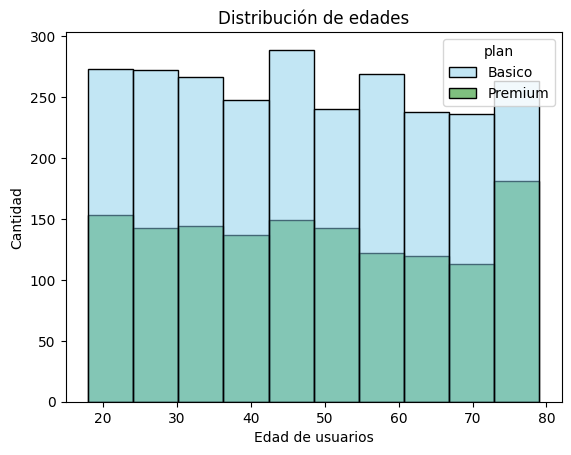

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', bins=10, palette=['skyblue', 'green'])
plt.title('Distribución de edades')
plt.xlabel('Edad de usuarios')
plt.ylabel('Cantidad')
plt.show()

💡Insights: 
- Distribución marcadamente uniforme a lo largo del eje X, lo que demuestra que la adopción del servicio es transversal y no presenta sesgos demográficos significativos entre los clientes de 20 a 80 años.

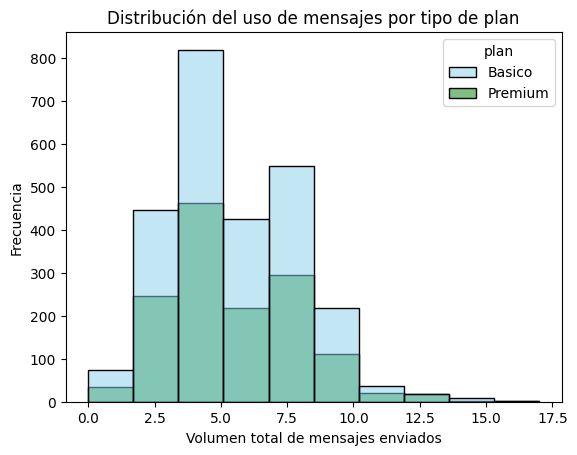

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', bins=10, palette=['skyblue', 'green'])
plt.title('Distribución del uso de mensajes por tipo de plan')
plt.xlabel('Volumen total de mensajes enviados')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- La distribución presenta una clara asimetría positiva (sesgo hacia la derecha), indicando que la gran mayoría de los clientes presenta un comportamiento de bajo consumo. Independientemente del tipo de plan, el bloque principal de usuarios concentra su actividad enviando entre 3 y 7 mensajes durante el periodo analizado, donde se alcanzan los picos máximos de frecuencia. A partir de los 8 mensajes, el volumen de usuarios cae drásticamente, consolidando una minoría en la "cola larga" que realiza usos intensivos superiores a los 10 mensajes, sin que el plan Premium demuestre un apalancamiento claro hacia estos rangos de alto consumo.

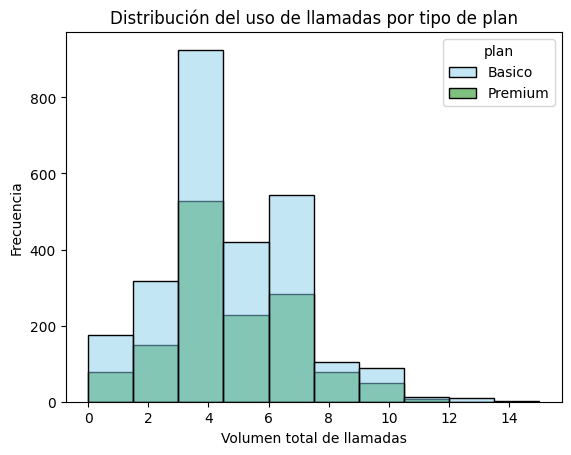

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', bins=10, palette=['skyblue', 'green'])
plt.title('Distribución del uso de llamadas por tipo de plan')
plt.xlabel('Volumen total de llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Distribución con un comportamiento marcadamente bimodal, revelando que no existe un único patrón central de consumo, sino dos grupos de actividad frecuentes. Independientemente del tipo de plan, el comportamiento de los clientes se concentra en dos grandes bloques: un primer segmento mayoritario que realiza alrededor de 4 llamadas (el pico más alto) y un segundo segmento recurrente que efectúa 6 llamadas.
A partir de las 8 llamadas, la curva cae abruptamente consolidando un claro sesgo hacia la derecha en la "cola larga", demostrando que las cuotas de uso intensivo o de alto volumen (10 a 14 llamadas) representan un grupo minoritario de usuarios, sin una tracción significativa ni siquiera por parte de los clientes del plan Premium.

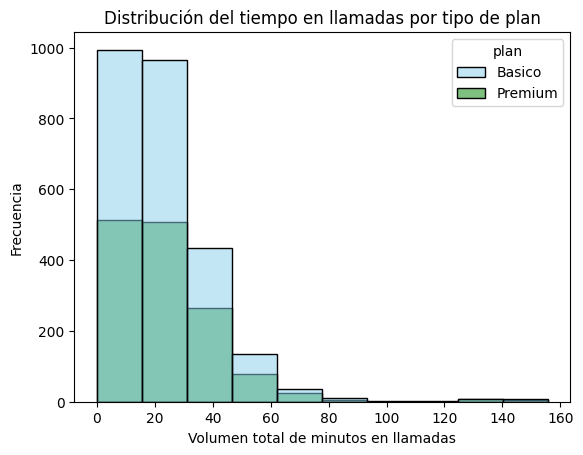

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', bins=10, palette=['skyblue', 'green'])
plt.title('Distribución del tiempo en llamadas por tipo de plan')
plt.xlabel('Volumen total de minutos en llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- La distribución exhibe una pronunciada asimetría positiva (sesgo hacia la derecha), indicando que la vasta mayoría de los usuarios presenta un comportamiento de bajo consumo en tiempo de voz. Independientemente de estar suscritos al plan Básico o Premium, el tiempo en línea de la mayor parte de la cartera se concentra fuertemente en el rango de 0 a 30 minutos por periodo analizado. A partir de la barrera de los 30 minutos, la frecuencia de usuarios decae de forma drástica, consolidando una minoría de clientes de uso intensivo en la "cola larga" (extendiéndose marginalmente hasta más de 140 minutos), sin que el plan Premium demuestre ser un factor diferenciador para los consumos de alta duración.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

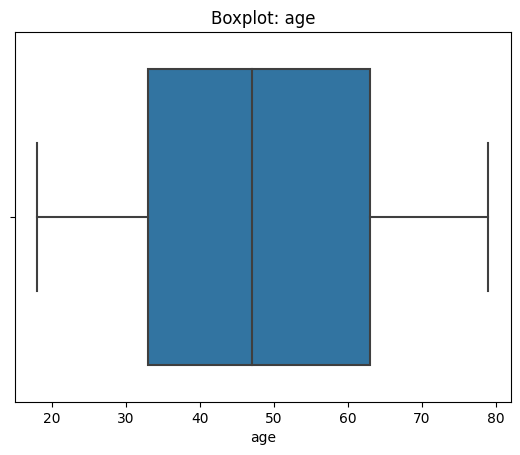

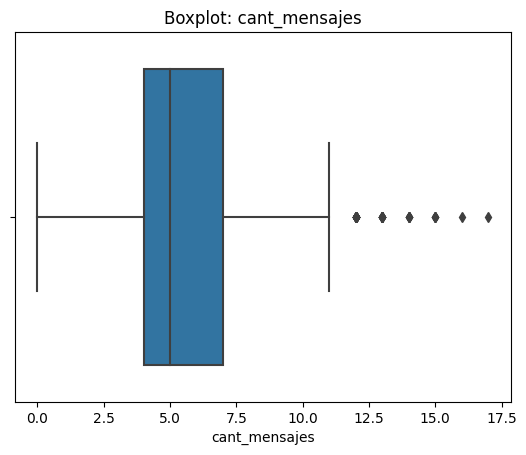

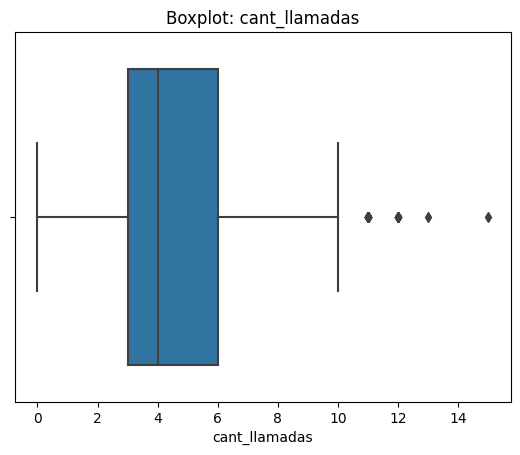

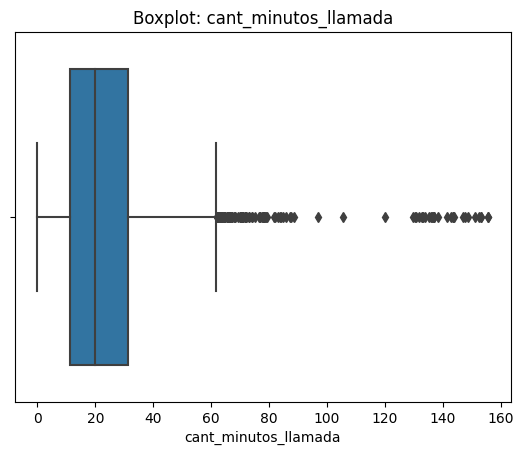

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: No presenta outliers (la distribución se mantiene limpia dentro de los límites del bigote).
- cant_mensajes: Sí presenta outliers (se observan varios puntos o rombos a la derecha del límite superior del bigote).
- cant_llamadas: Sí presenta outliers (se observan puntos aislados en el rango superior derecho, fuera del bigote).
- cant_minutos_llamada: Sí presenta outliers (se observa una densa concentración de puntos atípicos extendiéndose fuertemente hacia la derecha, superando el límite superior esperado).

In [35]:
# Calcular límites con el método IQR
columnas_limites = []
columnas_numericas = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_numericas:
    q1= user_profile[col].quantile(0.25)
    q3= user_profile[col].quantile(0.75)
    IQR= q3-q1
    limite_inferior= q1 - 1.5*IQR
    limite_superior= q3 + 1.5*IQR
    columnas_limites.append({'columna': col, 'limite_inferior': limite_inferior, 'limite_superior': limite_superior})
print(columnas_limites)

[{'columna': 'cant_mensajes', 'limite_inferior': -0.5, 'limite_superior': 11.5}, {'columna': 'cant_llamadas', 'limite_inferior': -1.5, 'limite_superior': 10.5}, {'columna': 'cant_minutos_llamada', 'limite_inferior': -19.35, 'limite_superior': 61.870000000000005}]


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_numericas].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- Se deben mantener. Aunque el límite superior teórico es de 11.5, el valor máximo registrado en la base de datos es de 17.0 mensajes. En un periodo de facturación (mensual, por ejemplo), enviar 17 mensajes de texto   es un comportamiento de consumo completamente factible y no representa un error de sistema ni un dato atípico imposible que requiera eliminación.
- cant_llamadas: mantener o no outliers, porqué?
- Se deben mantener. El límite superior dictado por el IQR es de 10.5, pero el valor máximo real encontrado es de 15 llamadas. Similar a los mensajes, realizar 15 llamadas en el periodo evaluado es un volumen de       actividad bajo/moderado para un cliente de telecomunicaciones, confirmando que estos outliers estadísticos son clientes reales de mayor actividad, no anomalías.
- cant_minutos_llamada: mantener o no outliers, porqué?
- Se deben mantener. El IQR marca el límite en 61.87 minutos, mientras que el consumo máximo registrado llega a los 155.69 minutos. Hablar un poco más de dos horas y media (155 min) en un ciclo completo es un          consumo estándar e incluso bajo para la industria, validando que esta "cola larga" de la distribución representa a los clientes de mayor valor (heavy users) y no errores de captura.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]
categorias = ['Bajo uso', 'Uso medio']
user_profile['grupo_uso'] = np.select(condiciones, categorias, default='Alto uso')


In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
condiciones = [
    (user_profile['age'] < 30),
    (user_profile['age'] < 60)
]
categorias = ['Joven', 'Adulto']
user_profile['grupo_edad'] = np.select(condiciones, categorias, default='Adulto Mayor')


In [43]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

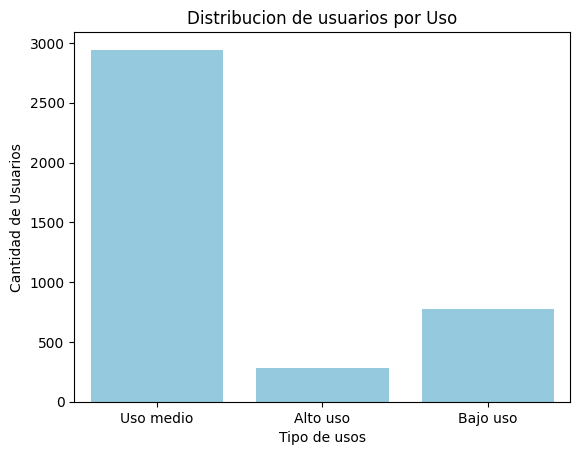

In [44]:
# Visualización de los segmentos por uso
sns.countplot(x=user_profile['grupo_uso'], color='skyblue')
plt.title('Distribucion de usuarios por Uso')
plt.xlabel("Tipo de usos")
plt.ylabel("Cantidad de Usuarios")
plt.show()

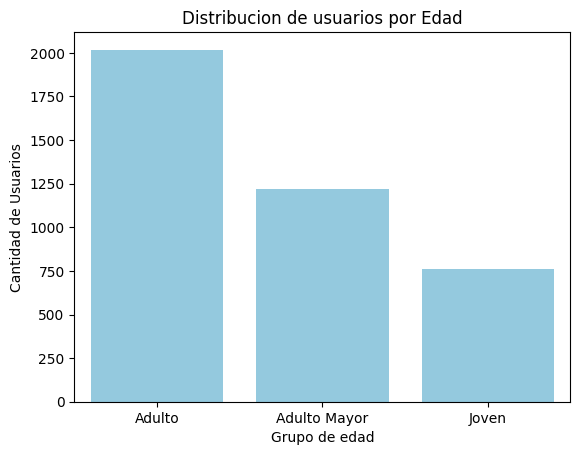

In [45]:
# Visualización de los segmentos por edad
sns.countplot(x=user_profile['grupo_edad'], color='skyblue')
plt.title('Distribucion de usuarios por Edad')
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de Usuarios")
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Valores centinela y atípicos en Users: Se corrigieron 55 registros (1.38%) en age que contenían el valor centinela -999 (reemplazados por la mediana) y 96 registros (2.4%) en city con el carácter inválido ?          (convertidos a NA). Además, se identificaron 40 registros (1.0%) con fechas futuras erróneas del año 2026 en reg_date, los cuales se asignaron como NaT.
- Completitud y nulos estructurales: La columna churn_date presentó 3,534 nulos (88.35%), los cuales identifican a la masa de usuarios activos y no deben ser eliminados. En usage, los nulos en duration (55.19%) y      length (44.74%) se clasificaron como MAR (Missing At Random), derivados de la exclusión mutua de eventos: las llamadas no generan volumen de texto y los mensajes no consumen minutos.
- Gestión de Outliers: Se detectaron valores atípicos en cant_mensajes (máx. 17 vs. límite IQR 11.5), cant_llamadas (máx. 15 vs. límite IQR 10.5) y cant_minutos_llamada (máx. 155.69 min vs. límite IQR 61.87 min). Se   decidió mantener el 100% de estos datos, ya que representan usuarios reales de alto consumo (heavy users) y no errores de registro.


🔍 **Segmentos por Edad**
- Adulto (30-59 años): Constituye el núcleo comercial de ConnectaTel al concentrar el 50% de la cartera (~2,000 clientes), siendo el grupo de mayor estabilidad operativa.
- Adulto Mayor (≥60 años): Representa el 30% de la base (~1,200 clientes), demostrando una retención y adopción madura del servicio.
- Joven (<30 años): Equivale al 20% restante (~750 clientes), configurándose como el segmento con mayor potencial de crecimiento a largo plazo.


📊 **Segmentos por Nivel de Uso**
- Uso medio: Segmento dominante con el 74% de la masa de clientes (~2,950 usuarios), caracterizado por una actividad constante pero moderada
- Bajo uso: Representa el 19% de la cartera (~770 usuarios), agrupando a clientes subutilizadores de sus cuotas contractuales.
- Alto uso (Heavy Users): Concentra al 7% de los usuarios (~280 clientes), siendo el perfil de mayor consumo operativo.


➡️ Esto sugiere que ...
Existe una oportunidad de optimización comercial: el 64.9% de los clientes suscribe el plan Básico y el 35.1% el Premium, mientras que el 74% de la base mantiene un perfil de Uso medio. Los segmentos más valiosos para ConnectaTel son el grupo de Alto uso (por su volumen transaccional y necesidad de cuotas amplias) y el grupo demográfico de Adultos (30-59 años) (al representar la mitad de la facturación recurrente).

💡 **Recomendaciones**
- Ajuste de oferta para Uso Medio: Desarrollar planes intermedios o empaquetados que ofrezcan cuotas adicionales de minutos/mensajes por un incremento marginal de precio, incentivando la migración (upselling) del      74% de usuarios en uso medio.
- Estrategia de fidelización para Heavy Users: Crear incentivos comerciales y beneficios exclusivos en el plan Premium dirigidos al 7% de Alto uso, asegurando la retención de estos clientes de mayor valor.
- Captación en el segmento Joven: Diseñar planes móviles flexibles orientados a consumo digital o mensajería masiva para elevar la captación de usuarios menores de 30 años (actualmente en 20%).

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`